# Documento de trabajo para diferencias en diferencias

Descripcion del análsis: Escribe la descripcion y objetivo del análisis.

Justificación del modelo: Escribe la justificación de porque se eligió este modelo

Autor: Escribe tu nombre aquí

Fecha de creación: Escribe la fecha de creación (YYYY-MM-DD)

Fecha de última actualización: Escribe la fecha de creación (YYYY-MM-DD)

In [ ]:
import os
from pyprojroot import here

os.chdir(here() / "src")
print("Nuevo directorio:", os.getcwd())

In [ ]:
# Librerias necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [ ]:
# Definimos la semilla para la reproducibilidad
np.random.seed(42)

# Definimos la fecha de intervencion
fecha_intervencion = pd.to_datetime('01/10/2024', dayfirst=True)

In [106]:
# Leemos la base de datos y especificaqmos el tipo de datos 
df= pd.read_csv('Colocación_MiPymes-Grandes-Personales.csv')

df['Fecha'] = pd.to_datetime(df['Fecha'], dayfirst=True, errors="coerce")
df['Mediana'] = pd.to_numeric(df['Mediana'], errors="coerce")
df['Pequeña'] = pd.to_numeric(df['Pequeña'], errors="coerce")
df['Micro'] = pd.to_numeric(df['Micro'], errors="coerce")
df['Grandes'] = pd.to_numeric(df['Grandes'], errors="coerce")
df['Personales'] = pd.to_numeric(df['Personales'], errors="coerce")

df['MiPymes'] = df['Micro'] + df['Pequeña'] + df['Mediana']
df['Pymes'] = df['Pequeña'] + df['Mediana']

# Añadimos cero a los null para Personales y que se pueda calcular correctamente el acumulado 12 meses
df = df.fillna(0)
df.tail()

,Fecha,Mediana,Pequeña,Micro,Grandes,Personales,MiPymes,Pymes
106,2025-07-01,23230.5,57335.1,13912.4,671577.6,0.0,94478.0,80565.6
107,2025-08-01,22635.9,56902.4,11164.3,645066.7,46944.7,90702.6,79538.3
108,2025-09-01,23951.2,59627.2,12580.8,657789.5,0.0,96159.2,83578.4
109,2025-10-01,24005.7,59926.6,11623.8,634541.4,47976.6,95556.1,83932.3
110,2025-11-01,23567.5,58310.7,11673.5,557026.9,0.0,93551.7,81878.2


In [107]:
# Calculamos el acumulado bimestral para que ambos esten medidos con la misma frecuencia
df["Micro_ac_bim"] = df["Micro"].rolling(window=12).sum()
df["Pequeña_ac_bim"] = df["Pequeña"].rolling(window=12).sum()
df["Mediana_ac_bim"] = df["Mediana"].rolling(window=12).sum()

df["MiPymes_ac_bim"] = df["MiPymes"].rolling(window=12).sum()
df["Pymes_ac_bim"] = df["Pymes"].rolling(window=12).sum()
df["Grandes_ac_bim"] = df["Grandes"].rolling(window=12).sum()
df["Personales_ac_bim"] = df["Personales"].rolling(window=12).sum()

In [108]:
# Filtramos algunos datos para no sesgar la estimacion
df = df.loc[df['Personales']!=0]
df = df.loc[df['Fecha']>=pd.to_datetime('01/01/2019')]

In [109]:
df_var = df.copy()
df_var.set_index('Fecha', inplace=True)

df_var = (df_var/df_var.shift(6)-1)*100


df_var.dropna(inplace=True)


# Visualización y definición del grupo de control

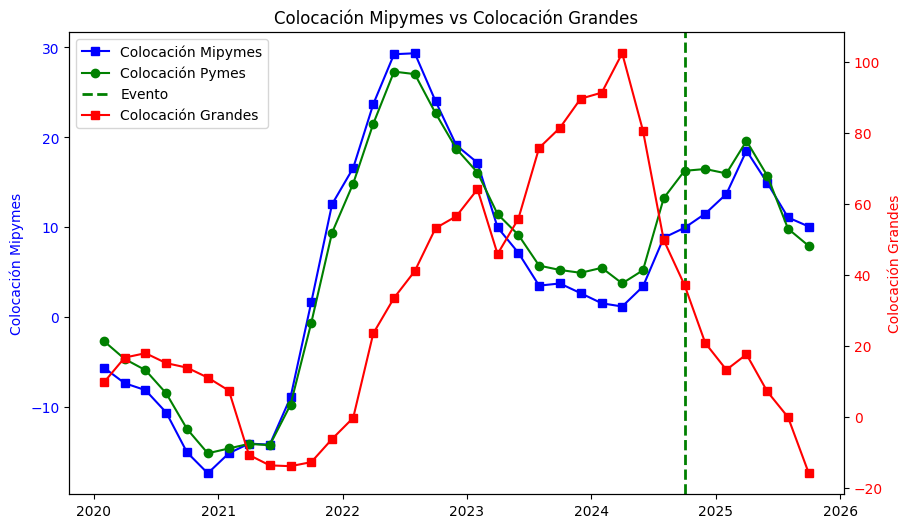

In [110]:
fig, ax1 = plt.subplots(figsize=(10,6))

# Primer eje Y
ax1.plot(df_var.index, df_var['MiPymes_ac_bim'], label='Colocación Mipymes', marker='s', linestyle='-', color='blue')
ax1.plot(df_var.index, df_var['Pymes_ac_bim'], label='Colocación Pymes', marker='o', linestyle='-', color='green')
ax1.set_ylabel("Colocación Mipymes", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Segundo eje Y
ax2 = ax1.twinx()
ax2.plot(df_var.index, df_var['Grandes_ac_bim'], label='Colocación Grandes', marker='s', linestyle='-', color='red')
ax2.set_ylabel("Colocación Grandes", color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Linea vertical indicadno fecha
ax1.axvline(fecha_intervencion, color='green', linestyle='--', linewidth=2, label='Evento')

# Título
plt.title("Colocación Mipymes vs Colocación Grandes")

# Leyenda (unimos las de ambos ejes)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.show()

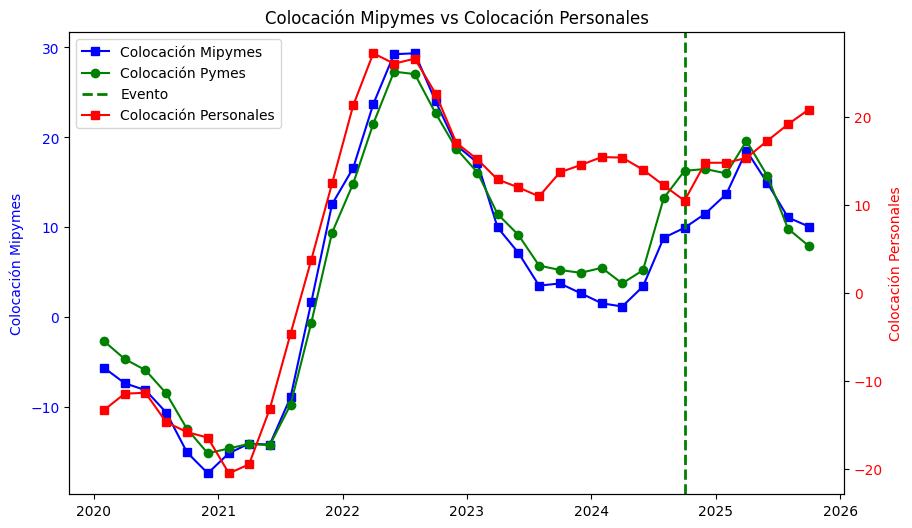

In [111]:
fig, ax1 = plt.subplots(figsize=(10,6))

# Primer eje Y
ax1.plot(df_var.index, df_var['MiPymes_ac_bim'], label='Colocación Mipymes', marker='s', linestyle='-', color='blue')
ax1.plot(df_var.index, df_var['Pymes_ac_bim'], label='Colocación Pymes', marker='o', linestyle='-', color='green')
ax1.set_ylabel("Colocación Mipymes", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Segundo eje Y
ax2 = ax1.twinx()
ax2.plot(df_var.index, df_var['Personales_ac_bim'], label='Colocación Personales', marker='s', linestyle='-', color='red')
ax2.set_ylabel("Colocación Personales", color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Linea vertical indicadno fecha
ax1.axvline(fecha_intervencion, color='green', linestyle='--', linewidth=2, label='Evento')

# Título
plt.title("Colocación Mipymes vs Colocación Personales")

# Leyenda (unimos las de ambos ejes)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.show()


# Preparación de variables

In [112]:
# Crear la variable 'grupo_tratamiento': 1 para Mipymes, 0 para Personales
# Para un análisis de DID, necesitamos que los datos estén en un formato 'largo'
# Creamos un nuevo DataFrame para reestructurar los datos

df_largo = pd.DataFrame()
df_largo['Fecha'] = df['Fecha']
df_largo['valor'] = df['MiPymes_ac_bim']
df_largo['grupo'] = 'tratamiento'

df_temp = pd.DataFrame()
df_temp['Fecha'] = df['Fecha']
df_temp['valor'] = df['Personales_ac_bim']
df_temp['grupo'] = 'control'

df_largo = pd.concat([df_largo, df_temp], ignore_index=True)

# Crear la variable binaria para el grupo
df_largo['grupo_tratamiento'] = (df_largo['grupo'] == 'tratamiento').astype(int)

# Volver a crear la variable 'post_tratamiento' en el nuevo DataFrame
df_largo['post_tratamiento'] = (df_largo['Fecha'] > fecha_intervencion).astype(int)

# Crear la variable de interacción
df_largo['did'] = df_largo['grupo_tratamiento'] * df_largo['post_tratamiento']

df_largo.head()

,Fecha,valor,grupo,grupo_tratamiento,post_tratamiento,did
0,2019-02-01,813792.1,tratamiento,1,0,0
1,2019-04-01,815437.0,tratamiento,1,0,0
2,2019-06-01,814320.5,tratamiento,1,0,0
3,2019-08-01,809026.3,tratamiento,1,0,0
4,2019-10-01,804411.3,tratamiento,1,0,0


In [113]:
# Paso 3: Estructurar y ejecutar el modelo de regresión
# Definir las variables dependientes e independientes
Y = df_largo['valor']
X = df_largo[['grupo_tratamiento', 'post_tratamiento', 'did']]
X = sm.add_constant(X)  # Añadir la constante para la intersección

# Correr el modelo de regresión OLS (Mínimos Cuadrados Ordinarios)
modelo = sm.OLS(Y, X)
resultados = modelo.fit()

# Resultados

In [114]:
# Paso 4: Obtener e interpretar los resultados
print(resultados.summary())

# El coeficiente de interés es el de la variable 'did'.
efecto_did = resultados.params['did']
p_valor_did = resultados.pvalues['did']

print(f"\nEl efecto del tratamiento (Diferencia en Diferencias) es: {efecto_did:.2f}")
print(f"El p-valor asociado es: {p_valor_did:.4f}")

if p_valor_did < 0.05:
    print("\nEl efecto es estadísticamente significativo. Esto sugiere que el tratamiento tuvo un impacto causal.")
else:
    print("\nEl efecto no es estadísticamente significativo. Esto sugiere que no hay evidencia de un impacto causal del tratamiento.")

                            OLS Regression Results                            
Dep. Variable:                  valor   R-squared:                       0.965
Model:                            OLS   Adj. R-squared:                  0.964
Method:                 Least Squares   F-statistic:                     715.8
Date:              mié., 28 ene. 2026   Prob (F-statistic):           1.22e-56
Time:                        14:31:58   Log-Likelihood:                -1024.1
No. Observations:                  82   AIC:                             2056.
Df Residuals:                      78   BIC:                             2066.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const              1.689e+05   1.11e+0